# 09 · Inferência: latência, vazão, custo e onde está o gargalo

> **Capítulo 9 do livro:** *Inference Optimization*.
> O modelo existe e é bom o bastante (caps. 3 a 8). Agora ele precisa **responder rápido, para muita gente, sem custar uma fortuna**. A pergunta deixa de ser "qual a qualidade?" e passa a ser "quanto tempo, quanto dinheiro, em qual hardware?".

**Objetivo:** entender o que limita a velocidade de um modelo de linguagem (**memória**, não conta), implementar e **medir** o cache de chaves e valores (KV cache), simular **lotes**, verificar a **decodificação especulativa** e comparar caches de resposta, terminando com a conta de **borda contra nuvem**.

## Antes de começar

- **Você precisa saber:** notebook 02 (atenção, parâmetros, memória) e 07 (quantização).
- **O que é real e o que é simulado:** o decodificador com e sem cache é **código real** (numpy, pesos aleatórios; o que importa é a mecânica e o tempo medido nesta máquina). A decodificação especulativa roda de verdade sobre modelos de n-gramas. **A fila de atendimento é uma simulação**, com tempos montados pela aritmética de memória. **Os números de hardware e preço são ilustrativos**: troque pelos seus.
- **Tempo:** 70 minutos.

## Mapa do notebook

1. As três métricas e o que as limita
2. Duas fases: prefill e decodificação
3. KV cache: medido, e o que ele custa em memória
4. Lotes: vazão contra latência
5. Decodificação especulativa
6. Caches: de prefixo e de resposta
7. Custo: borda contra nuvem
8. Em que ordem otimizar

In [1]:
import sys, pathlib, random
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
%matplotlib inline
import matplotlib.pyplot as plt

## 1. As três métricas e o que as limita

- **TTFT** (tempo até o primeiro token): o que o operador sente como "demorou para começar a responder". Depende do **prefill**.
- **TPOT** (tempo por token de saída): o que define se o texto "flui". Depende da **decodificação**.
- **Vazão** (tokens por segundo do sistema todo): o que define quantas pessoas o mesmo equipamento atende, e portanto o **custo por pedido**.

Elas competem: aumentar a vazão com lotes costuma piorar a latência de cada um. E **a média engana**: o que importa para quem usa é o **p95** (o pior caso comum), como no capítulo 4.

## 2. Duas fases: prefill e decodificação

Para responder, o modelo faz duas coisas bem diferentes:

1. **Prefill:** lê o prompt inteiro de uma vez. Muitos tokens em paralelo, **muita conta** por byte de peso lido: é limitado pela **capacidade de cálculo** (FLOPs).
2. **Decodificação:** gera **um token por vez**. Cada token precisa ler **todos os pesos** da memória para fazer pouca conta: é limitado pela **largura de banda da memória**.

A consequência é uma conta de uma linha: na decodificação, `tokens por segundo ≈ largura de banda / bytes dos pesos`. Isso explica por que **quantizar acelera** (menos bytes por passo) e por que **GPU cara com pouca banda não adianta**.

In [2]:
from aiind.inference import *
import numpy as np
# VALORES ILUSTRATIVOS: ordem de grandeza. Troque pelos do seu hardware.
hw = {"equipamento de borda (~100 GB/s)": 100, "GPU de estação (~900 GB/s)": 900, "GPU de datacenter (~2000 GB/s)": 2000}
P = 7e9
print(f"decodificação de um modelo de 7 B, um usuário (tokens por segundo, TETO teórico):")
print(f"{'hardware':36s} {'16 bits':>9s} {'8 bits':>8s} {'4 bits':>8s}")
for nome, bw in hw.items():
    print(f"{nome:36s} " + " ".join(f"{decode_tps(P, b, bw):8.0f}" for b in (16, 8, 4)))
print("\nprefill de um prompt de 1000 tokens (segundos), GPU de ~100 TFLOPs a 50 % de uso:", round(prefill_seconds(P, 1000, 100), 2))
print("o mesmo prompt em um equipamento de borda de ~5 TFLOPs:", round(prefill_seconds(P, 1000, 5), 2))

decodificação de um modelo de 7 B, um usuário (tokens por segundo, TETO teórico):
hardware                               16 bits   8 bits   4 bits
equipamento de borda (~100 GB/s)            7       14       29
GPU de estação (~900 GB/s)                 64      129      257
GPU de datacenter (~2000 GB/s)            143      286      571

prefill de um prompt de 1000 tokens (segundos), GPU de ~100 TFLOPs a 50 % de uso: 0.28
o mesmo prompt em um equipamento de borda de ~5 TFLOPs: 5.6


### Pare e preveja

Se você quantiza um modelo de 16 para 4 bits, em quanto aumenta o teto de tokens por segundo na decodificação? E o tempo de prefill?

A decodificação fica **~4 vezes mais rápida** (4 vezes menos bytes por passo). O prefill **quase não muda**, porque é limitado por conta, não por memória (na prática, ele até pode ficar um pouco mais lento por causa da conversão de volta). **Cada fase pede uma otimização diferente.**

Dois cuidados com esses números: são **tetos** (o real fica abaixo: o cache de KV e o software também leem memória), e um prompt grande num equipamento de borda **demora segundos para começar** a responder, mesmo que depois flua.

## 3. KV cache: medido, e o que ele custa em memória

Ao gerar o token número *t*, a atenção precisa das chaves (K) e valores (V) de **todos os tokens anteriores**. Sem cache, o modelo **recalcula tudo** a cada token. Com cache, guarda K e V já calculados e só processa o token novo.

Aqui está um decodificador real em numpy (3 camadas, pesos aleatórios) gerando com e sem cache. Primeiro: as saídas são **idênticas**? Depois: o tempo.

saídas idênticas com e sem cache: True


  25 tokens: sem cache   0.01 s | com cache  0.005 s |   2.2x
  50 tokens: sem cache   0.03 s | com cache  0.009 s |   3.5x
 100 tokens: sem cache   0.12 s | com cache  0.020 s |   6.0x
 200 tokens: sem cache   0.57 s | com cache  0.048 s |  11.8x
 300 tokens: sem cache   1.74 s | com cache  0.089 s |  19.6x

conta de FLOPs de um modelo de 1 B, prompt 200 + 400 tokens novos:  sem cache 3.2e+14  com cache 8.0e+11


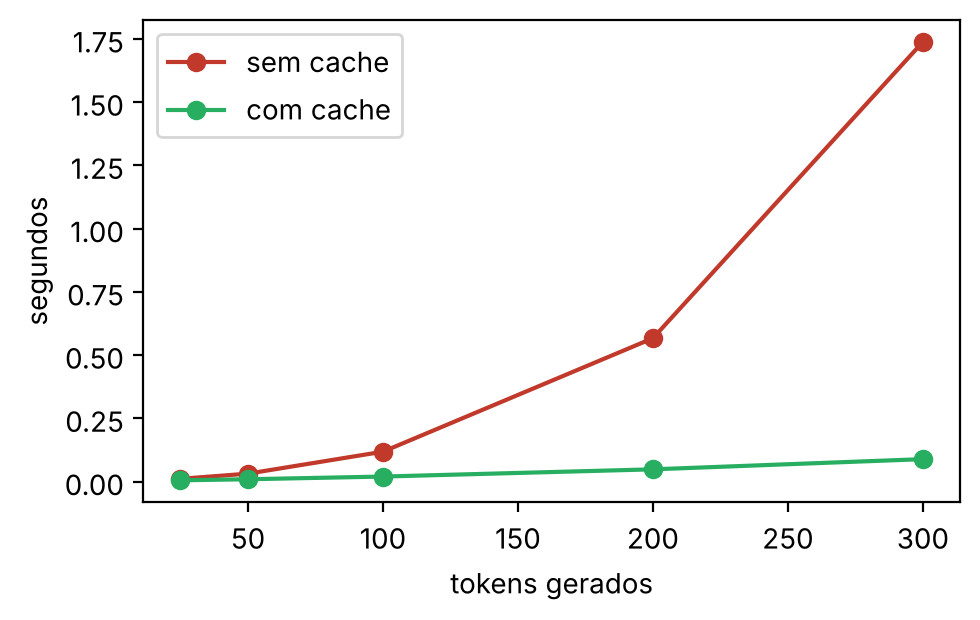

In [3]:
import time
m = TinyDecoder(seed=0); prompt = list(range(10))
print("saídas idênticas com e sem cache:", m.generate(prompt, 60, cache=True) == m.generate(prompt, 60, cache=False))
ns = [25, 50, 100, 200, 300]; t_sem, t_com = [], []
for n in ns:
    t0 = time.perf_counter(); m.generate(prompt, n, cache=False); t1 = time.perf_counter(); m.generate(prompt, n, cache=True); t2 = time.perf_counter()
    t_sem.append(t1 - t0); t_com.append(t2 - t1)
for n, a, b in zip(ns, t_sem, t_com): print(f"{n:4d} tokens: sem cache {a:6.2f} s | com cache {b:6.3f} s | {a / b:5.1f}x")
fig, ax = plt.subplots(figsize=(5, 3.2)); ax.plot(ns, t_sem, "o-", c="#c0392b", label="sem cache"); ax.plot(ns, t_com, "o-", c="#27ae60", label="com cache")
ax.set_xlabel("tokens gerados"); ax.set_ylabel("segundos"); ax.legend(); plt.tight_layout()
print("\nconta de FLOPs de um modelo de 1 B, prompt 200 + 400 tokens novos:  sem cache", f"{flops_no_cache(1e9, 200, 400):.1e}", " com cache", f"{flops_decode(1e9, 400):.1e}")

- As saídas **são idênticas**: o cache é uma otimização **exata**, não uma aproximação.
- Sem cache o tempo **cresce com o quadrado** do comprimento (cada token reprocessa tudo); com cache cresce **linearmente**. A vantagem **aumenta com o comprimento**: cerca de 3 vezes em 50 tokens e 20 vezes em 300. (Os tempos exatos dependem da máquina; a forma da curva não.)

Mas o cache **custa memória**, e ela cresce com o contexto **e com o número de usuários simultâneos**:

`bytes por token = 2 (K e V) × camadas × cabeças de KV × dimensão da cabeça × bytes por número`

In [4]:
# modelo de 7 B típico: 32 camadas, cabeça de 128; sem e com atenção agrupada (GQA: 8 cabeças de KV em vez de 32)
for nome, kvh in (("atenção completa (32 cabeças de KV)", 32), ("GQA (8 cabeças de KV)", 8)):
    por_tok = kv_cache_bytes(32, kvh, 128, 1)
    print(f"{nome:38s} {por_tok / 1e6:5.2f} MB por token | 4000 tokens: {kv_cache_bytes(32, kvh, 128, 4000) / 1e9:5.2f} GB por usuário | 32 usuários: {32 * kv_cache_bytes(32, kvh, 128, 4000) / 1e9:6.1f} GB")
print("\npesos do mesmo modelo em 16 bits: 14 GB. Em 4 bits: 3,5 GB.")

atenção completa (32 cabeças de KV)     0.52 MB por token | 4000 tokens:  2.10 GB por usuário | 32 usuários:   67.1 GB
GQA (8 cabeças de KV)                   0.13 MB por token | 4000 tokens:  0.52 GB por usuário | 32 usuários:   16.8 GB

pesos do mesmo modelo em 16 bits: 14 GB. Em 4 bits: 3,5 GB.


Com 32 usuários de 4000 tokens, o **cache (67 GB) passa dos pesos (14 GB)**. Por isso existem a **atenção agrupada** (GQA, 4 vezes menos cache), a **quantização do próprio cache** e o **janelamento** (esquecer o começo). Numa planta, a pergunta prática é: **quantos usuários simultâneos, com que contexto?** O limite de atendimento costuma ser **memória**, não cálculo.

## 4. Lotes: vazão contra latência

A decodificação lê todos os pesos **uma vez por passo**, não importa quantos pedidos estão no passo. Então processar **vários pedidos juntos** (um **lote**) quase não aumenta o tempo do passo e multiplica a vazão. O problema é como formar o lote:

- **Um de cada vez:** simples, e a fila explode.
- **Lote estático:** espera encher (ou um tempo) e roda até **o mais longo terminar**; os curtos esperam parados ("bloqueio de cabeça de fila").
- **Lote contínuo:** a cada passo, pedidos novos **entram** e os que terminaram **saem**. É o que servidores de inferência modernos fazem.

Simulação (tempo do passo = leitura dos pesos 7 ms + 0,4 ms por pedido; saídas de comprimento variável; chegadas aleatórias, 60 s por carga):

 pedidos/s |         um por vez         |       lote estático        |       lote contínuo       
           |     p50     p95    tok/s |     p50     p95    tok/s |     p50     p95    tok/s
         1 |     2.7     5.7      123 |     1.2     3.2      123 |     0.7     2.0      124
         3 |    51.0   106.0      130 |     3.8     7.7      333 |     0.9     3.0      367
         6 |   131.1   240.6      130 |    28.0    52.6      350 |     1.2     4.3      658
        12 |   277.8   514.3      130 |    84.1   151.8      353 |    16.0    28.0      879


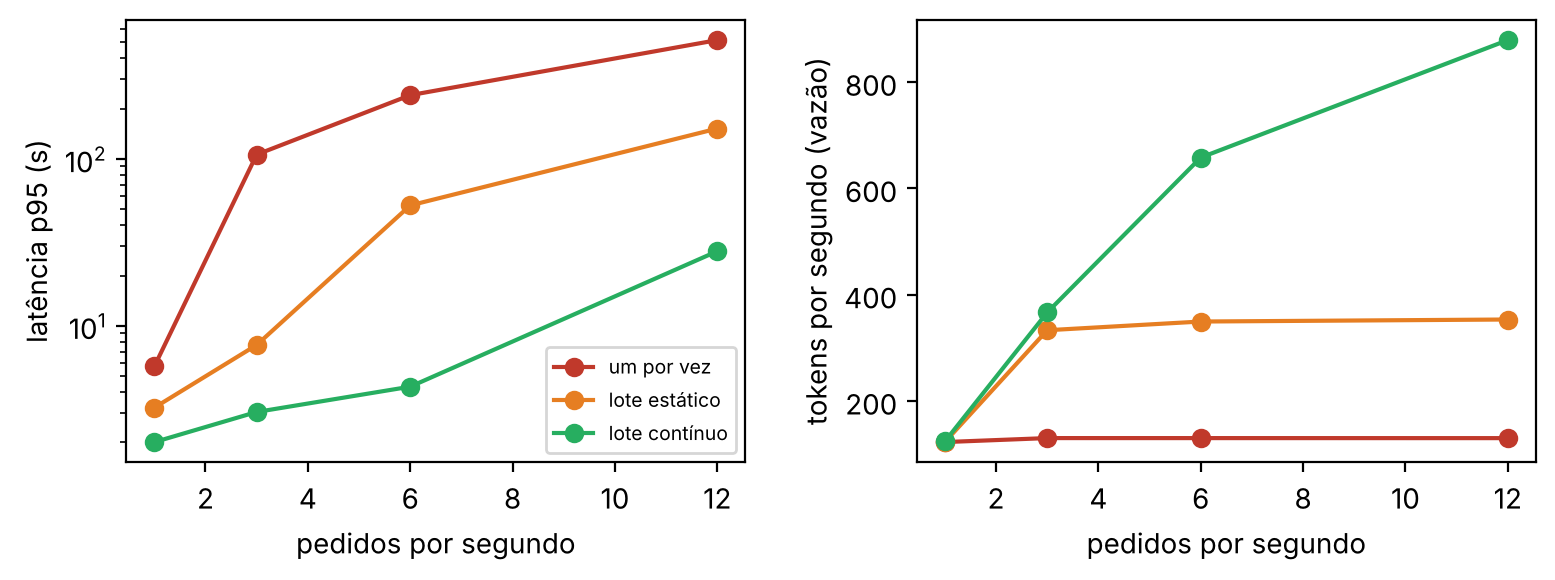

In [5]:
rates = [1, 3, 6, 12]; pols = ["one", "static", "continuous"]; nomes = {"one": "um por vez", "static": "lote estático", "continuous": "lote contínuo"}
res = {}
for pol in pols:
    for rate in rates:
        lat, tps = simulate_serving(make_requests(rate, 60, 1), pol); res[(pol, rate)] = (np.percentile(lat, 50), np.percentile(lat, 95), tps)
print(f"{'pedidos/s':>10s} | " + " | ".join(f"{nomes[p]:^26s}" for p in pols)); print(f"{'':>10s} | " + " | ".join(f"{'p50':>7s} {'p95':>7s} {'tok/s':>8s}" for _ in pols))
for rate in rates:
    print(f"{rate:10d} | " + " | ".join(f"{res[(p, rate)][0]:7.1f} {res[(p, rate)][1]:7.1f} {res[(p, rate)][2]:8.0f}" for p in pols))
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
for pol, cor in zip(pols, ["#c0392b", "#e67e22", "#27ae60"]):
    ax[0].plot(rates, [res[(pol, r)][1] for r in rates], "o-", c=cor, label=nomes[pol]); ax[1].plot(rates, [res[(pol, r)][2] for r in rates], "o-", c=cor, label=nomes[pol])
ax[0].set_yscale("log"); ax[0].set_xlabel("pedidos por segundo"); ax[0].set_ylabel("latência p95 (s)"); ax[1].set_xlabel("pedidos por segundo"); ax[1].set_ylabel("tokens por segundo (vazão)"); ax[0].legend(fontsize=7); plt.tight_layout()

- **Um por vez** satura em ~130 tokens/s e a latência vira minutos assim que a carga passa de 1 pedido por segundo.
- **Lote estático** triplica a vazão, mas a latência p95 continua alta (os curtos esperam o mais longo).
- **Lote contínuo** chega a ~880 tokens/s, mantém o p95 em ~4 s até 6 pedidos por segundo e só satura perto de 12 (p95 de 28 s). Mesmo hardware, outra política.

Isso é uma **simulação com tempos assumidos**: o que se transfere é a **forma** (vazão sobe com o lote, latência depende da política), não os números. Para o seu sistema, meça com a sua carga.

## 5. Decodificação especulativa

A decodificação é lenta porque gera **um token por passo caro**. A ideia: um **modelo pequeno (rascunho)** propõe vários tokens à frente, e o **modelo grande (alvo)** os **verifica todos num único passo**. Aceita-se cada token com probabilidade `min(1, p_alvo / p_rascunho)`; no primeiro recusado, sorteia-se o token correto a partir da diferença das distribuições. Se todos passam, ganha-se um token extra de graça.

O resultado importante: a saída tem **exatamente a distribuição do modelo grande**. Não é aproximação. Verificamos isso, e depois medimos o ganho com modelos de n-gramas (alvo de ordem 4, rascunhos de ordem 1, 2 e 3):

In [6]:
import random
from collections import Counter
from aiind.corpus import notes
from aiind.tinylm import NGram, word_tokens
seqs = [word_tokens(n) for n in notes(2000, 1)]
alvo = NGram(4).fit(seqs)

# 1) a distribuição é a do alvo? compara com o próprio alvo amostrando
rng = random.Random(0); N = 3000
rascunho = NGram(2).fit(seqs)
a = Counter(tuple(speculative(alvo, rascunho, rng, 3, 4)[0]) for _ in range(N)); b = Counter(tuple(alvo.generate(rng, max_len=3)) for _ in range(N)); c = Counter(tuple(alvo.generate(rng, max_len=3)) for _ in range(N))
tv = lambda x, y: 0.5 * sum(abs(x[k] - y[k]) / N for k in set(x) | set(y))
print(f"distância entre especulativo e alvo: {tv(a, b):.3f}   | entre dois sorteios do próprio alvo (ruído): {tv(b, c):.3f}")

# 2) ganho
print(f"\n{'rascunho':>10s} {'k':>3s} {'tokens por passo':>17s} {'aceitação (alfa)':>17s} {'ganho com rascunho a 5 %':>25s} {'a 30 %':>8s}")
for ordem in (1, 2, 3):
    rasc = NGram(ordem).fit(seqs)
    for k in (2, 4, 8):
        rng = random.Random(0); tot = ps = 0
        for _ in range(150):
            out, p = speculative(alvo, rasc, rng, 12, k); tot += 12; ps += p
        tpp = tot / ps; lo, hi = 0, 0.999
        for _ in range(40):
            mid = (lo + hi) / 2
            lo, hi = (mid, hi) if expected_tokens_per_pass(mid, k) < tpp else (lo, mid)
        print(f"{'ordem ' + str(ordem):>10s} {k:3d} {tpp:17.2f} {lo:17.2f} {speculative_speedup(lo, k, 0.05):25.2f}x {speculative_speedup(lo, k, 0.3):7.2f}x")

distância entre especulativo e alvo: 0.087   | entre dois sorteios do próprio alvo (ruído): 0.093

  rascunho   k  tokens por passo  aceitação (alfa)  ganho com rascunho a 5 %   a 30 %
   ordem 1   2              1.33              0.26                      1.21x    0.83x
   ordem 1   4              1.42              0.30                      1.18x    0.65x


   ordem 1   8              1.46              0.31                      1.04x    0.43x
   ordem 2   2              1.74              0.49                      1.58x    1.09x
   ordem 2   4              2.05              0.53                      1.71x    0.93x


   ordem 2   8              2.05              0.51                      1.47x    0.60x
   ordem 3   2              2.77              0.92                      2.52x    1.73x
   ordem 3   4              3.73              0.85                      3.11x    1.70x
   ordem 3   8              5.45              0.87                      3.90x    1.60x


- A distância para o alvo é **do tamanho do ruído** entre dois sorteios do próprio alvo: a distribuição é preservada.
- O ganho depende de **quão parecido o rascunho é com o alvo** (a taxa de aceitação α) e de **quão barato ele é** (o custo relativo). Com rascunho ruim (ordem 1, α ≈ 0,3) o ganho é pequeno e **vira perda** se o rascunho não for bem mais barato. Com rascunho bom (α ≈ 0,86) chega a 3 a 4 vezes.
- Mais tokens propostos (k) ajudam só se a aceitação for alta: com o rascunho de ordem 3, k = 8 rende 3,9x contra 3,1x de k = 4; com o de ordem 2, k maior **piora**.
- É a **mais promissora** quando o texto é **previsível** (formulários, relatórios com estrutura fixa); em texto criativo, α cai.

## 6. Caches: de prefixo e de resposta

**Cache de prefixo.** Todo pedido do seu assistente começa igual: instruções, regras, exemplos (capítulo 5). Se esse começo tem 800 tokens e a pergunta tem 30, **o prefill do começo se repete a cada pedido**. Guardar o estado (o KV) do começo e reaproveitá-lo corta quase todo o prefill:

In [7]:
sistema, pergunta = 800, 30
sem = prefill_seconds(7e9, sistema + pergunta, 100); com = prefill_seconds(7e9, pergunta, 100)
print(f"prefill por pedido (GPU de 100 TFLOPs): sem cache de prefixo {sem * 1000:.0f} ms | com {com * 1000:.0f} ms | economia {1 - com / sem:.0%}")
print(f"em equipamento de borda (5 TFLOPs): {prefill_seconds(7e9, sistema + pergunta, 5):.1f} s -> {prefill_seconds(7e9, pergunta, 5):.2f} s")

prefill por pedido (GPU de 100 TFLOPs): sem cache de prefixo 232 ms | com 8 ms | economia 96%
em equipamento de borda (5 TFLOPs): 4.6 s -> 0.17 s


Em APIs de nuvem, o mesmo princípio vira **desconto por prefixo repetido**; vale a pena **manter o começo do prompt estável** (não ponha data ou nome do usuário no começo).

**Cache de resposta.** Se a mesma pergunta chega de novo, nem precisa chamar o modelo. Mas o que conta como "a mesma pergunta"? Testamos quatro regras num fluxo de 800 perguntas de OEE (máquinas e dias repetidos, com três formas de escrever cada pergunta), medindo **quantas respostas vieram do cache** e **quantas dessas estavam erradas** (pergunta diferente tratada como igual):

In [8]:
s = query_stream(800, 1)
print(f"{len({k for _, k in s})} perguntas realmente distintas em {len(s)}\n")
print(f"{'regra do cache':44s} {'acertos do cache':>17s} {'dessas, erradas':>16s}")
for nome, modo, th in [("exata (texto normalizado)", "exact", 0), ("similar, limiar 0,5", "similar", .5), ("similar, limiar 0,7", "similar", .7), ("similar, limiar 0,9", "similar", .9), ("chave estruturada (o parser do capítulo 4)", "parsed", 0)]:
    h, w = run_cache(s, modo, th); print(f"{nome:44s} {h:17.0%} {w:16.0%}")

217 perguntas realmente distintas em 800

regra do cache                                acertos do cache  dessas, erradas


exata (texto normalizado)                                  54%               0%
similar, limiar 0,5                                        97%              92%
similar, limiar 0,7                                        93%              91%


similar, limiar 0,9                                        72%              63%
chave estruturada (o parser do capítulo 4)                 62%               0%


O resultado é um aviso: o cache por **similaridade de texto** aumenta os acertos, mas **a maioria deles está errada**, porque "OEE da prensa no dia 3" e "OEE da prensa no dia 4" (ou "peças" e "falha" da mesma máquina) são textos quase iguais com respostas diferentes. Números e entidades **não são pequenos detalhes**.

O que funciona é a **chave estruturada**: extrair (tipo de pergunta, máquina, dia) com regras e guardar a resposta sob essa chave. Aqui rende **62 % de acertos com 0 % de erros**, contra 54 % do cache exato. E o cache de resposta tem de respeitar a **validade**: um OEE de hoje muda ao longo do dia; ponha um prazo (TTL) ou invalide quando o dado muda.

## 7. Custo: borda contra nuvem

Rodar o modelo **no equipamento** (borda) ou **numa GPU alugada** ou **por API**? O custo por milhão de tokens depende de uma variável que muita gente esquece: a **utilização**. Uma GPU parada custa o mesmo que uma ocupada.

Premissas (**ilustrativas, troque pelas suas**): GPU alugada a US$ 2,00/h com a vazão da simulação do lote contínuo (~880 tokens/s); equipamento de borda de US$ 1.500 amortizado em 3 anos, ~28 tokens/s (modelo de 7 B em 4 bits, 100 GB/s); uma resposta tem 150 tokens.

In [9]:
gpu_h, gpu_tps = 2.0, 880
edge_h, edge_tps = 1500 / (3 * 365 * 24) + 0.01, decode_tps(7e9, 4, 100)       # amortização + energia aproximada
tok_por_resp = 150
print(f"{'utilização':>11s} | {'GPU alugada':^24s} | {'borda':^24s}")
print(f"{'':>11s} | {'US$/M tokens':>12s} {'US$/1000 resp.':>12s} | {'US$/M tokens':>12s} {'US$/1000 resp.':>12s}")
for u in (1.0, 0.5, 0.1, 0.02):
    g, e = cost_per_million(gpu_h, gpu_tps, u), cost_per_million(edge_h, edge_tps, u)
    print(f"{u:11.0%} | {g:12.2f} {g * tok_por_resp / 1000:12.3f} | {e:12.2f} {e * tok_por_resp / 1000:12.3f}")
print(f"\ncapacidade de uma GPU: {gpu_tps * 86400 / tok_por_resp:,.0f} respostas/dia | da borda: {edge_tps * 86400 / tok_por_resp:,.0f} respostas/dia")
print(f"custo FIXO por mês: GPU alugada US$ {gpu_h * 24 * 30:,.0f} | borda US$ {edge_h * 24 * 30:,.0f}")
pedidos = 300
print(f"com {pedidos} respostas por dia, a utilização seria {pedidos / (gpu_tps * 86400 / tok_por_resp):.2%} na GPU e {pedidos / (edge_tps * 86400 / tok_por_resp):.1%} na borda")

 utilização |       GPU alugada        |          borda          
            | US$/M tokens US$/1000 resp. | US$/M tokens US$/1000 resp.
       100% |         0.63        0.095 |         0.65        0.098
        50% |         1.26        0.189 |         1.30        0.196
        10% |         6.31        0.947 |         6.52        0.978
         2% |        31.57        4.735 |        32.61        4.891

capacidade de uma GPU: 506,880 respostas/dia | da borda: 16,457 respostas/dia
custo FIXO por mês: GPU alugada US$ 1,440 | borda US$ 48
com 300 respostas por dia, a utilização seria 0.06% na GPU e 1.8% na borda


- A **utilização** muda o custo por token em 50 vezes. Com a mesma utilização, o custo por token é parecido nas duas opções (~US$ 0,65 por milhão a 100 %); a diferença está no **custo fixo**: ~US$ 1.440 por mês de GPU contra ~US$ 48 da borda. Para um assistente de chão de fábrica com **algumas centenas de perguntas por dia**, a GPU dedicada fica em 0,06 % de uso e se paga mal: **API paga por uso ou equipamento de borda** ganham.
- A **borda** tem teto baixo de vazão (algumas dezenas de tokens por segundo), mas **custo fixo previsível**, **latência sem rede** e **o dado não sai da planta**. Vale quando a carga é pequena e constante, ou quando a política de OT proíbe enviar dados para fora.
- **Nuvem** vale quando a carga é grande, variável, ou o modelo precisa ser grande.
- Falta na conta: ativações, o cache de KV, o custo do prefill, a engenharia para manter o servidor, e o custo de erro. Use como ponto de partida, não como decisão.

## 8. Em que ordem otimizar

1. **Meça primeiro:** TTFT, TPOT e p95 por tipo de pedido, e **onde o tempo vai** (prefill, decodificação, rede, fila).
2. **Gaste menos tokens:** prompt mais curto, saída limitada (`max_tokens`), formato estruturado (capítulo 5). É a otimização **mais barata e sem perda de qualidade**.
3. **Caches:** de prefixo (sempre) e de resposta (com chave estruturada e validade).
4. **Lote contínuo** no servidor, se houver mais de um usuário.
5. **Quantização** (capítulo 7): meça a qualidade no seu conjunto de avaliação antes de adotar.
6. **Modelo menor** para os casos fáceis, e o grande só quando preciso (roteamento do capítulo 4).
7. **Decodificação especulativa**, quando a saída é previsível e há um bom rascunho.

Cada passo tem **custo de complexidade**; pare quando a meta de latência e custo estiver atendida.

## Erros comuns

- **Otimizar a média** e ignorar o p95.
- **Medir só a decodificação** e esquecer o prefill (que domina com prompts longos, principalmente na borda).
- **Esquecer o cache de KV** na conta de memória.
- **Cache de resposta por similaridade de texto**, sem proteger números e entidades.
- **Cache sem validade** servindo OEE de ontem como se fosse de agora.
- **Comparar custo de GPU a 100 % de uso** quando o uso real é de 2 %.
- **Quantizar e acelerar sem medir a qualidade.**
- **Generalizar uma simulação** (tempos assumidos) como se fosse medição.

## Confira o que ficou

**1. Por que a decodificação é limitada pela memória e o prefill pelo cálculo?**

<details><summary>Ver resposta</summary>

Na decodificação cada passo lê todos os pesos para processar um token só (pouca conta por byte lido); no prefill muitos tokens são processados juntos para os mesmos pesos.

</details>

**2. Por que quantizar para 4 bits acelera a decodificação em cerca de 4 vezes?**

<details><summary>Ver resposta</summary>

Há 4 vezes menos bytes de pesos para ler por passo, e o passo é limitado pela largura de banda da memória.

</details>

**3. O KV cache muda a saída do modelo?**

<details><summary>Ver resposta</summary>

Não: as saídas são idênticas. Troca-se memória por tempo, evitando recalcular os tokens anteriores.

</details>

**4. Por que o lote contínuo supera o estático?**

<details><summary>Ver resposta</summary>

Pedidos entram e saem a cada passo, então os curtos não esperam o mais longo terminar e o hardware não fica ocioso.

</details>

**5. A decodificação especulativa altera o que o modelo diz?**

<details><summary>Ver resposta</summary>

Não: a regra de aceitação e rejeição preserva exatamente a distribuição do modelo grande; só muda a velocidade.

</details>

**6. Por que um cache de resposta por similaridade de texto é perigoso?**

<details><summary>Ver resposta</summary>

Perguntas que diferem por um número, uma máquina ou o tipo de medida têm textos quase iguais e respostas diferentes, e o cache devolve a resposta errada.

</details>

**7. Por que a utilização importa tanto no custo por token?**

<details><summary>Ver resposta</summary>

O custo da GPU é fixo por hora; a poucos pedidos o custo se divide por poucos tokens, e o custo por token sobe na proporção inversa da utilização.

</details>

## Exercícios

1. **Contexto:** meça o tempo de `generate` com e sem cache para prompts de 10, 100 e 500 tokens. Onde o prefill passa a dominar?
2. **Memória:** quantos usuários de 8000 tokens cabem numa GPU de 24 GB com um modelo de 7 B em 4 bits, com e sem GQA?
3. **Lote:** na simulação, varie `max_batch` (4, 16, 64) no lote contínuo. Onde a vazão para de subir? Por quê?
4. **Latência de cauda:** inclua um pedido muito longo de vez em quando (saída de 2000 tokens). O que acontece com o p95 de cada política?
5. **Especulativa:** acrescente um rascunho que erra a cada 10 tokens e meça se ainda vale a pena para custo relativo 0,1.
6. **Cache com validade:** acrescente um prazo (TTL) ao cache da seção 6 e uma atualização de dados a cada 100 perguntas. Quantas respostas velhas foram servidas com e sem prazo?
7. **Decisão:** com 300 perguntas por dia, 200 tokens por resposta, e a premissa de preço do seu fornecedor, qual opção é mais barata: API, GPU alugada ou borda?

## Glossário

- **TTFT:** tempo até o primeiro token da resposta.
- **TPOT:** tempo por token de saída.
- **Vazão:** tokens por segundo do sistema todo.
- **Prefill:** leitura paralela do prompt.
- **Decodificação:** geração de um token por vez.
- **KV cache:** chaves e valores da atenção guardados para não recalcular.
- **GQA:** atenção em que várias cabeças de consulta compartilham as mesmas chaves e valores (cache menor).
- **Lote contínuo:** pedidos entram e saem do lote a cada passo.
- **Decodificação especulativa:** rascunho propõe, modelo grande verifica em um passo.
- **Cache de prefixo:** reaproveitar o estado do começo repetido do prompt.
- **TTL:** prazo de validade de uma entrada de cache.
- **Utilização:** fração do tempo em que o hardware faz trabalho útil.

## Próximo passo

**Notebook 10, capítulo 10 (Arquitetura de sistemas de IA e feedback do usuário):** juntar tudo numa arquitetura (roteamento, cache, guardas, observabilidade) e fechar o ciclo com o feedback dos operadores, que alimenta a avaliação e o dado.